# Can They Afford to Repay? Affordability-Based Default Risk
### Testing the core fintech-lending idea on 1.3 million real loans

Traditional lending leans on the credit score: a backward-looking measure of how someone has handled debt before. A growing part of the industry argues the more important question is **affordability**, whether someone can actually afford the repayments given their income and existing obligations. This project tests that idea directly, on **1.35 million real, completed Lending Club loans**.

**The headline result:** affordability features on their own (income, payment-to-income, debt-to-income, loan size) predict default **better than a credit score and full bureau record** (ROC-AUC 0.70 vs 0.62), and the two together are better still. Even among borrowers with an identical FICO score, those with worse affordability default far more often.

**Built on real outcomes, with leakage removed.** Only loans that have finished (fully paid, or charged off) are used, and every post-origination field (payments made, recoveries, updated FICO) is dropped, so the model only sees what a lender would know at the point of decision.

## Why this is set up the way it is
- **Affordability, defined from income.** The dataset has borrower income, the monthly instalment, and reported debt-to-income, so affordability can be measured properly: payment-to-income, loan-to-income, and DTI, joint-aware for joint applications.
- **A fair credit-vs-affordability test.** The same model (XGBoost) is trained three times, on credit-and-bureau features only, on affordability features only, and on both, so any difference is down to the features, not the algorithm.
- **No leakage and no circularity.** Post-loan performance fields are excluded, and so are Lending Club's own grade and interest rate (which already encode its internal risk model). The model has to earn its signal from raw borrower attributes.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from scipy.stats import ks_2samp
from xgboost import XGBClassifier
import shap, warnings; warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
RND = 42

df = pd.read_parquet("data/lending_affordability.parquet")
base = df["default"].mean()
print(f"{len(df):,} completed loans | default rate {base:.1%} | {int(df['issue_year'].min())}-{int(df['issue_year'].max())}")

AFFORD = ["annual_inc_eff","dti_eff","payment_to_income","loan_to_income","installment","loan_amnt","term_months","emp_length_num"]
CREDIT = ["fico","delinq_2yrs","inq_last_6mths","revol_util","open_acc","pub_rec","total_acc","credit_history_yrs"]
BOTH = AFFORD + CREDIT

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1,348,094 completed loans | default rate 20.0% | 2007-2018


## 1. The affordability gradient
The simplest version of the idea: the more of someone's income a loan consumes, the more likely they are to default. It holds cleanly across three different affordability measures, default rises monotonically with each.

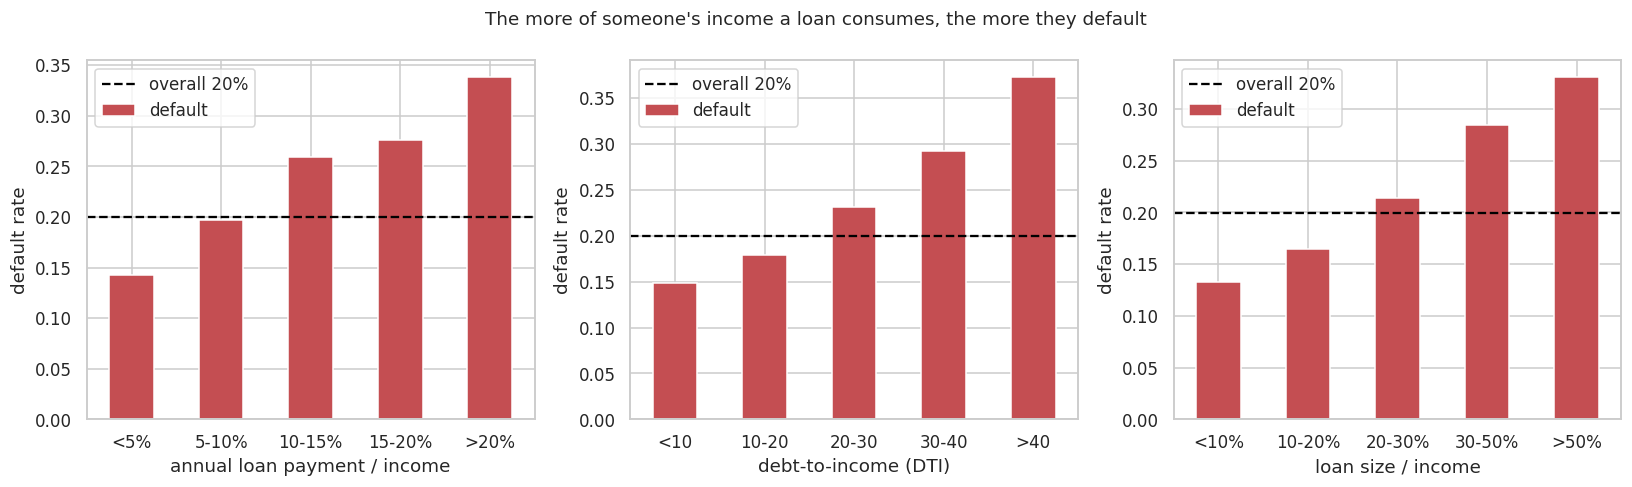

In [2]:
fig, ax = plt.subplots(1,3,figsize=(15,4.5))
def grad(col,bins,labels,axis,xlabel):
    g = df.groupby(pd.cut(df[col],bins=bins,labels=labels))["default"].mean()
    g.plot(kind="bar",ax=axis,color="#c44e52"); axis.axhline(base,ls="--",color="black",label=f"overall {base:.0%}")
    axis.set_xlabel(xlabel); axis.set_ylabel("default rate"); axis.legend(); axis.tick_params(axis="x",rotation=0)
grad("payment_to_income",[0,.05,.10,.15,.20,2],["<5%","5-10%","10-15%","15-20%",">20%"],ax[0],"annual loan payment / income")
grad("dti_eff",[0,10,20,30,40,100],["<10","10-20","20-30","30-40",">40"],ax[1],"debt-to-income (DTI)")
grad("loan_to_income",[0,.1,.2,.3,.5,5],["<10%","10-20%","20-30%","30-50%",">50%"],ax[2],"loan size / income")
fig.suptitle("The more of someone's income a loan consumes, the more they default",fontsize=12); plt.tight_layout(); plt.show()

## 2. Affordability adds signal the credit score misses
This is the crux. If affordability were just a proxy for creditworthiness, it would add nothing once you know the FICO score. It does not work out that way. Reading **down** a column, default falls as the credit score rises (creditworthiness matters). Reading **across** a row, default rises as affordability worsens, **at the same credit score**. A 760+ borrower with a stretched budget is riskier than a 660 borrower with plenty of room.

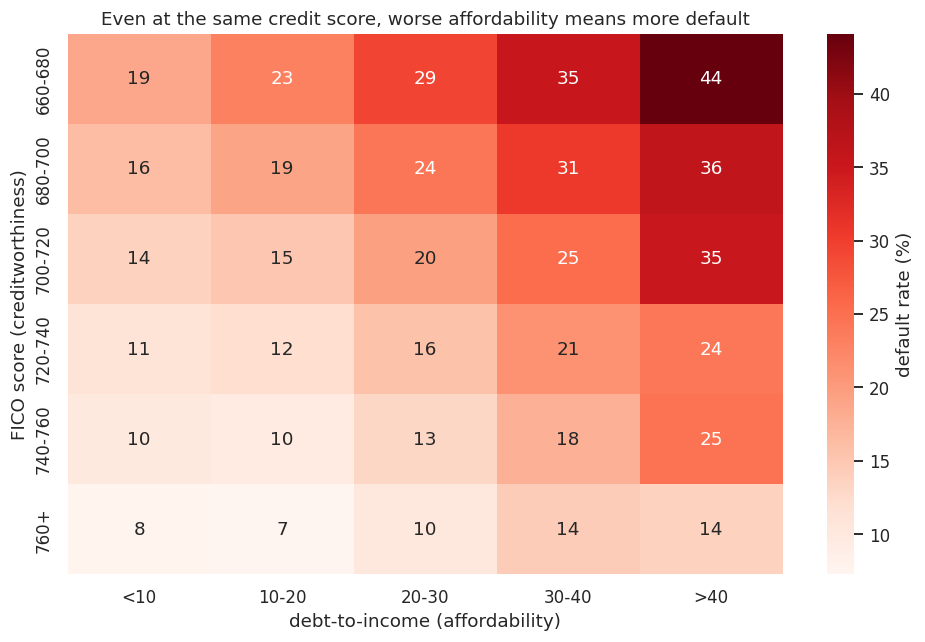

In [3]:
fico_bins=[660,680,700,720,740,760,850]; fico_lab=["660-680","680-700","700-720","720-740","740-760","760+"]
dti_bins=[0,10,20,30,40,100]; dti_lab=["<10","10-20","20-30","30-40",">40"]
piv = df.assign(fb=pd.cut(df["fico"],fico_bins,labels=fico_lab), db=pd.cut(df["dti_eff"],dti_bins,labels=dti_lab)) \
        .groupby(["fb","db"])["default"].mean().unstack()
plt.figure(figsize=(9,6)); sns.heatmap(piv*100,annot=True,fmt=".0f",cmap="Reds",cbar_kws={"label":"default rate (%)"})
plt.xlabel("debt-to-income (affordability)"); plt.ylabel("FICO score (creditworthiness)")
plt.title("Even at the same credit score, worse affordability means more default"); plt.tight_layout(); plt.show()

## 3. The test: credit score vs affordability vs both
The same XGBoost model, trained on three feature sets. The result is the point of the whole project: **affordability features alone out-predict the credit score and the full bureau record**, and combining the two is best. A no-skill model would score 0.20 on PR-AUC (the default rate).

Predicting default (no-skill PR-AUC = 0.200):


  Credit score + bureau    ROC-AUC 0.617 | PR-AUC 0.271


  Affordability only       ROC-AUC 0.699 | PR-AUC 0.361


  Both combined            ROC-AUC 0.706 | PR-AUC 0.371


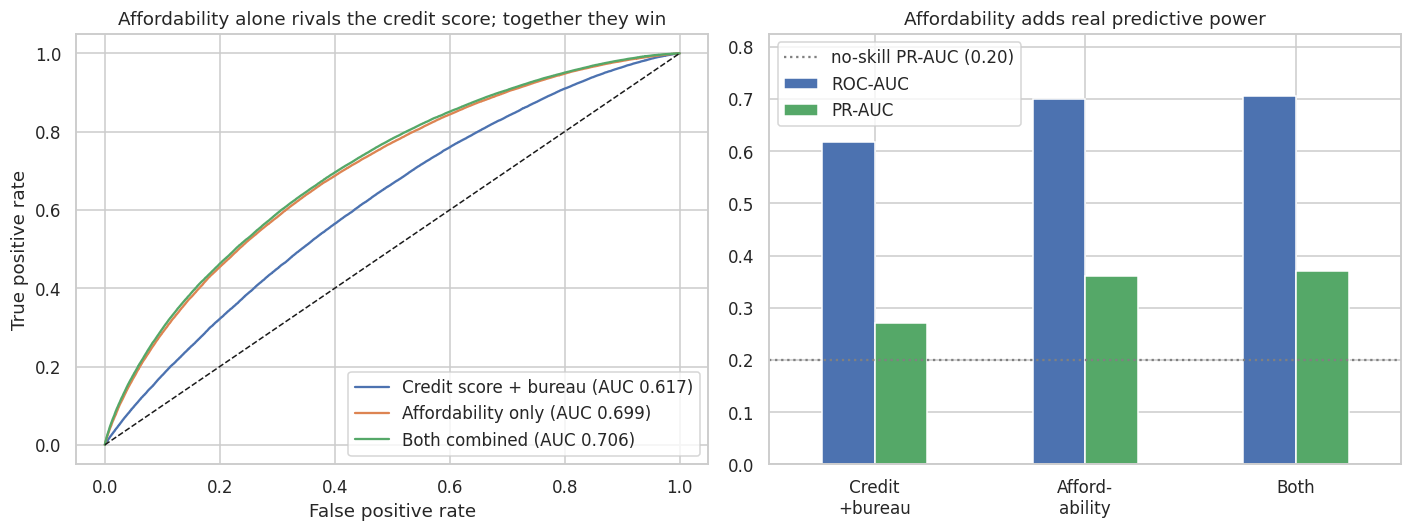

In [4]:
Xtr,Xte,ytr,yte = train_test_split(df[BOTH], df["default"], test_size=0.25, stratify=df["default"], random_state=RND)
spw = (ytr==0).sum()/(ytr==1).sum()
def run(feats,name):
    m=XGBClassifier(n_estimators=300,max_depth=5,learning_rate=0.05,subsample=0.9,colsample_bytree=0.8,
                    scale_pos_weight=spw,eval_metric="aucpr",tree_method="hist",random_state=RND,n_jobs=4)
    m.fit(Xtr[feats],ytr); p=m.predict_proba(Xte[feats])[:,1]
    print(f"  {name:24s} ROC-AUC {roc_auc_score(yte,p):.3f} | PR-AUC {average_precision_score(yte,p):.3f}")
    return m,p,roc_auc_score(yte,p),average_precision_score(yte,p)
print(f"Predicting default (no-skill PR-AUC = {base:.3f}):")
m_cr,p_cr,auc_cr,ap_cr = run(CREDIT,"Credit score + bureau")
m_af,p_af,auc_af,ap_af = run(AFFORD,"Affordability only")
m_bo,p_bo,auc_bo,ap_bo = run(BOTH,"Both combined")

fig,ax=plt.subplots(1,2,figsize=(13,5))
for name,p,col in [("Credit score + bureau",p_cr,"#4c72b0"),("Affordability only",p_af,"#dd8452"),("Both combined",p_bo,"#55a868")]:
    fpr,tpr,_=roc_curve(yte,p); ax[0].plot(fpr,tpr,c=col,label=f"{name} (AUC {roc_auc_score(yte,p):.3f})")
ax[0].plot([0,1],[0,1],"k--",lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("Affordability alone rivals the credit score; together they win"); ax[0].legend()
comp=pd.DataFrame({"ROC-AUC":[auc_cr,auc_af,auc_bo],"PR-AUC":[ap_cr,ap_af,ap_bo]},index=["Credit\n+bureau","Afford-\nability","Both"])
comp.plot(kind="bar",ax=ax[1],color=["#4c72b0","#55a868"]); ax[1].set_ylim(0,max(auc_bo,0.75)*1.1)
ax[1].axhline(base,ls=":",color="grey",label=f"no-skill PR-AUC ({base:.2f})"); ax[1].set_title("Affordability adds real predictive power")
ax[1].tick_params(axis="x",rotation=0); ax[1].legend(); plt.tight_layout(); plt.show()

## 4. What the combined model keys on
SHAP on the combined model shows a healthy mix: loan **term** (sixty-month loans are far riskier than thirty-six), the **credit score**, and then a stack of **affordability** signals, payment-to-income, instalment size, DTI, loan amount, sitting right alongside the credit features. Neither view alone tells the whole story.

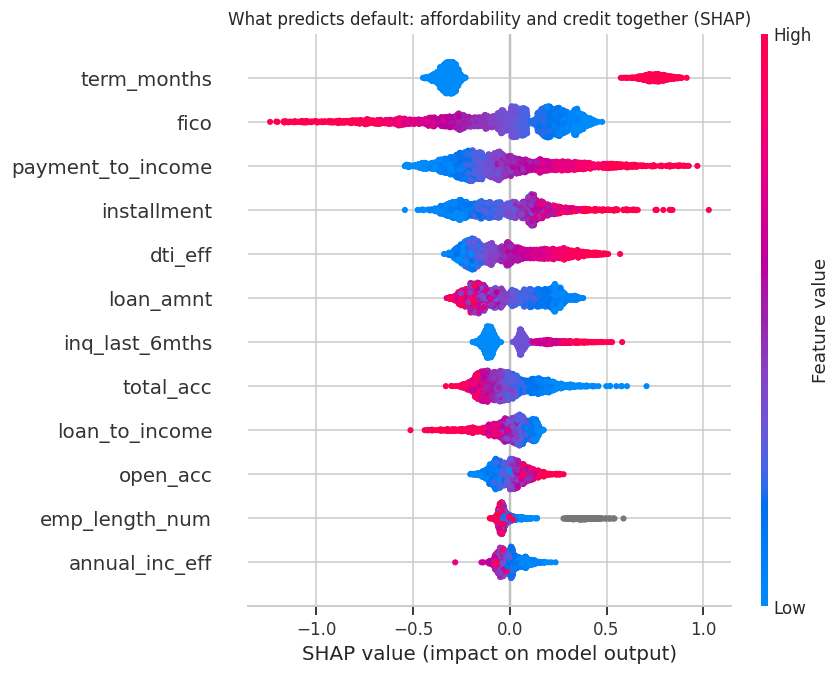

Top drivers:
term_months          0.422
fico                 0.269
payment_to_income    0.216
installment          0.175
dti_eff              0.166
loan_amnt            0.156
inq_last_6mths       0.119
total_acc            0.113


In [5]:
samp = Xte.sample(3000, random_state=RND); sv = shap.TreeExplainer(m_bo).shap_values(samp)
shap.summary_plot(sv, samp, show=False, max_display=12)
plt.title("What predicts default: affordability and credit together (SHAP)", fontsize=11); plt.tight_layout(); plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=samp.columns).sort_values(ascending=False)
print("Top drivers:"); print(imp.head(8).round(3).to_string())

## 5. Income, on its own, tracks default
Sorting borrowers into income deciles, default falls steadily from the lowest income band to the highest, a reminder that income is not just a denominator in a ratio but a risk signal in its own right.

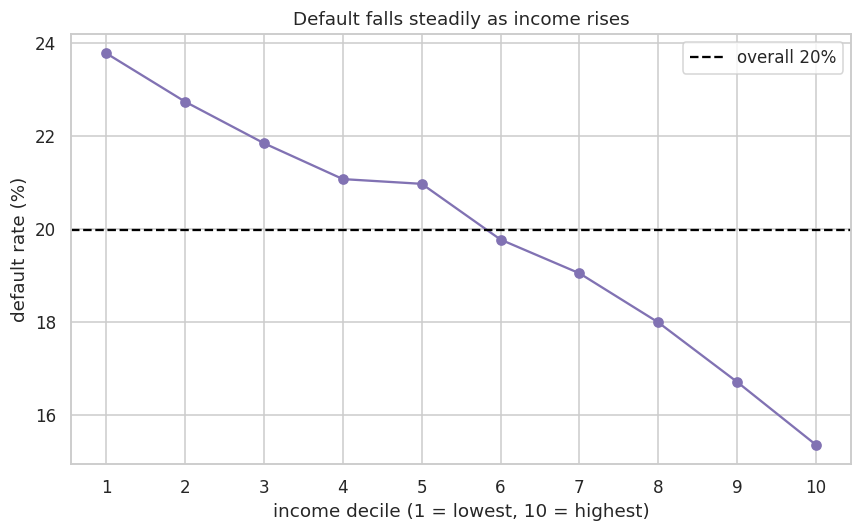

In [6]:
dec = df.groupby(pd.qcut(df["annual_inc_eff"],10,labels=False))["default"].mean()
plt.figure(figsize=(8,5)); plt.plot(range(1,11), dec.values*100, "o-", color="#8172b3")
plt.axhline(base*100,ls="--",color="black",label=f"overall {base:.0%}")
plt.xlabel("income decile (1 = lowest, 10 = highest)"); plt.ylabel("default rate (%)")
plt.title("Default falls steadily as income rises"); plt.legend(); plt.xticks(range(1,11)); plt.tight_layout(); plt.show()

## 6. How well the combined model separates outcomes
The two predicted-risk distributions, for loans that were repaid and loans that defaulted, with a KS statistic of 0.30. That is modest, and expectedly so: Lending Club has already screened out the weakest applicants, so the surviving population is harder to separate than a general one. The ranking is real, but this is a genuinely hard problem, not a solved one.

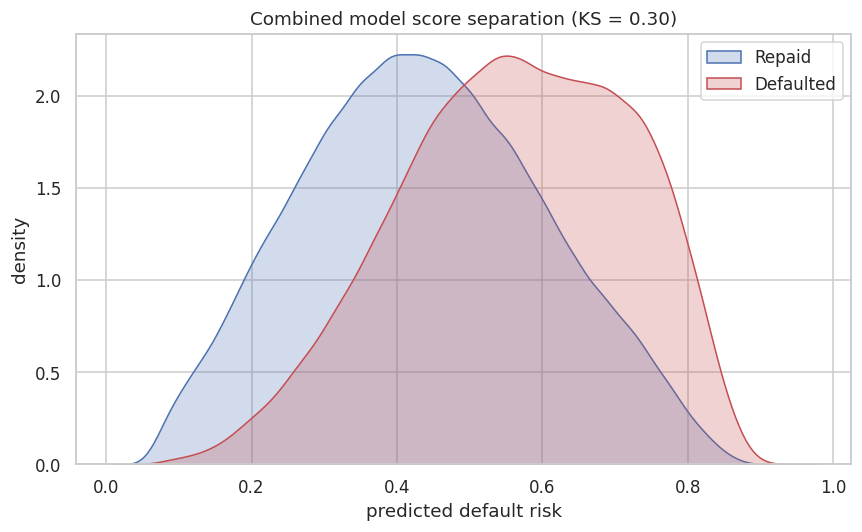

In [7]:
ks = ks_2samp(p_bo[yte==1], p_bo[yte==0]).statistic
plt.figure(figsize=(8,5))
sns.kdeplot(p_bo[yte==0], fill=True, color="#4c72b0", label="Repaid", clip=(0,1))
sns.kdeplot(p_bo[yte==1], fill=True, color="#c44e52", label="Defaulted", clip=(0,1))
plt.xlabel("predicted default risk"); plt.ylabel("density")
plt.title(f"Combined model score separation (KS = {ks:.2f})"); plt.legend(); plt.tight_layout(); plt.show()

## Key findings
1. **Affordability out-predicts the credit score here.** On its own, affordability reaches ROC-AUC 0.70 versus 0.62 for a credit score plus full bureau record; combined, 0.71.
2. **Affordability is not a proxy for the credit score.** At a fixed FICO band, default still climbs sharply as debt-to-income rises, so affordability carries information the score does not.
3. **The gradient is consistent.** Default rises monotonically with payment-to-income, DTI and loan-to-income, and falls steadily with income.
4. **Loan term and payment burden dominate** the combined model, alongside the credit score.

## Limitations
- **Survivorship in the data.** Lending Club already declined the riskiest applicants, so this models repayment among the approved, which compresses how separable the population is (the modest KS reflects that).
- **Self-reported income**, only partly verified, so affordability ratios carry some noise.
- **Scores would need calibrating** before being read as probabilities of default.
- **A US platform, 2007-2018.** The affordability *principle* travels; the exact thresholds do not.

---
*Data: Lending Club accepted-loans dataset (2007-2018), via Kaggle. Built as a portfolio project.*